In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import random
import seaborn as sns
import numpy as np

from tqdm import tqdm
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import confusion_matrix, precision_score
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
import torch
import torch.nn as nn

from src.modelos import MLP_clasificacion
from src.metricas import tabla_metricas, evaluar_metricas_clasificacion_binaria
from src.utils import df_features_to_numpy, df_target_to_numpy, make_dataloaders
from src.graficos import plot_confusion_matrix, plot_learning_curves_logistic_regression, plot_comparacion_metricas, plot_aceptacion_subplots
from src.splitting import split_estratificado_autor

# Cargo el dataset ya procesado

In [3]:
#LEO TEST
chunks_test = pd.read_json("set_test_1.json", lines=True, chunksize=100_000)
chunk_list = []
for chunk in chunks_test:
    chunk_list.append(chunk)
df_test = pd.concat(chunk_list, ignore_index=True)

#LEO VAL
chunks_val = pd.read_json("set_val_1.json", lines=True, chunksize=100_000)
chunk_list = []
for chunk in chunks_val:
    chunk_list.append(chunk)
df_val = pd.concat(chunk_list, ignore_index=True)

#LEO TRAIN
chunks_train = pd.read_json("set_train_1.json", lines=True, chunksize=100_000)
chunk_list = []
for chunk in chunks_train:
    chunk_list.append(chunk)
df_train = pd.concat(chunk_list, ignore_index=True)

## Preparacion de los datos
Al darnos cuenta de que la poca cantidad de datos de algunas clases no nos permitia hacer buenas predicciones, decidimos intentar otro metodo: clasificar el libro segun si va a ser aceptado por el publico (rating > 3.5) o no. Este podria ser un modelo muy usado por las editoriales, para decidir si aceptar un manuscrito, por ejemplo. <br> <br>
Para este modelo, vamos a seguir la logica de las otras predicciones, es decir:
- definir un baseline
- mejorar los modelos pero no las features
- mejorar los modelos y las features

In [4]:
#features que no van a ser usadas
df_train = df_train.drop(columns = ["description", "title", "language_code", "ratings_count", "authors", "format_group", "genres", "title_key", "title_text"])
df_val = df_val.drop(columns = ["description", "title", "language_code", "ratings_count", "authors", "format_group", "genres", "title_key", "title_text"])

In [5]:
generos = ["fiction", "non fiction", "fantasy", "science fiction", "mystery", "thriller", "romance", "horror", "historical", "young adult", "children", "adventure", "contemporary", "dystopian", "paranormal", "urban", "crime", "biography", "memoir", "self help", "history", "psychology", "poetry", "classics", "graphic novel", "short stories", "humor", "religion"]
features_base = ["is_series", "publication_year", "num_pages", 'AUDIO', 'COMIC', 'EBOOK', 'HARDCOVER', 'OTHER', 'PAPERBACK', "language_code_ang", "language_code_en", "language_code_en-CA", "language_code_en-GB", "language_code_en-US", "language_code_eng", "language_code_enm", "language_code_gem", "language_code_sco", "cantidad_generos"] + generos

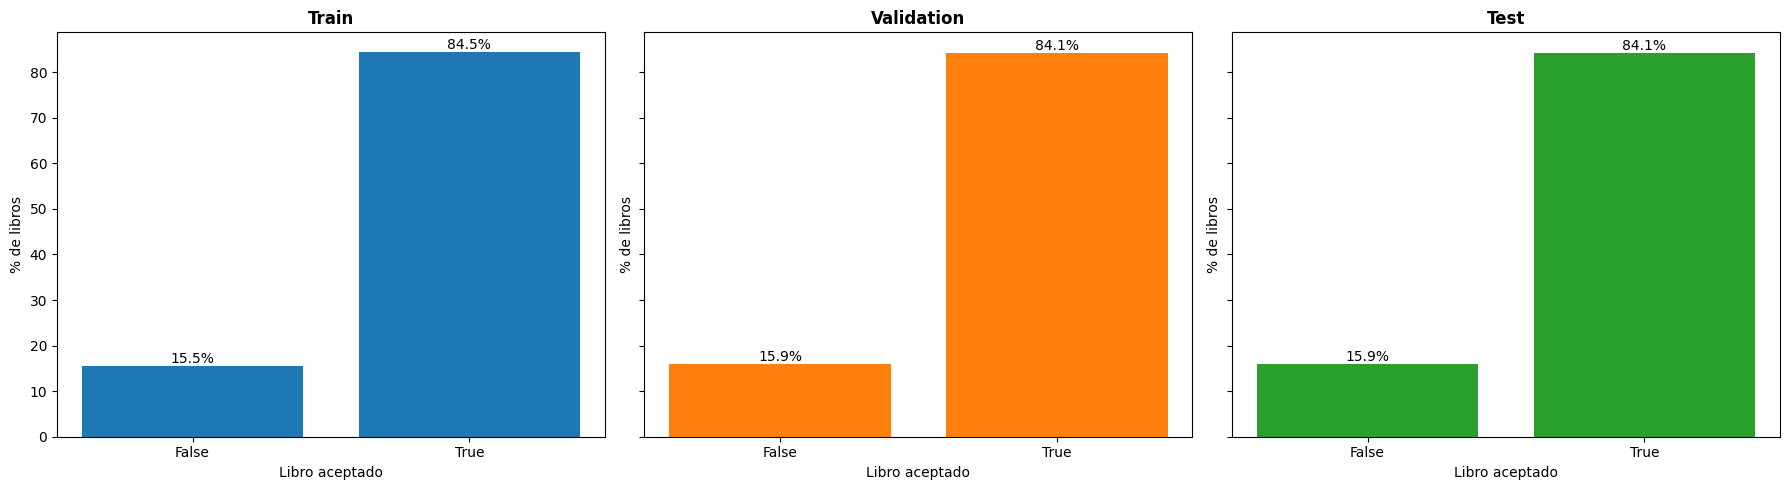

In [6]:
def clasificar_aceptacion(rating):
    return rating > 3.5
    
df_train["aceptado"] = df_train["average_rating"].apply(clasificar_aceptacion)
df_val["aceptado"] = df_val["average_rating"].apply(clasificar_aceptacion)
df_test["aceptado"] = df_test["average_rating"].apply(clasificar_aceptacion)

plot_aceptacion_subplots(df_train, df_val, df_test)

# Modelo base con features base

In [ ]:
#Me quedo solo con las features necesarias para el modelo base y las estandarizo
dfs = [df_train, df_val, df_test]
y_train, y_val, y_test = df_target_to_numpy("aceptado", dfs)
X_train, X_val, X_test = df_features_to_numpy(features_base, dfs)

#estandarizo los datos
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val) #escala X_val con los valores sacados de X_train
X_test_scaled = scaler.transform(X_test)

## Sin rebalanceo

,Train,Validation
Accuracy,0.845098,0.841335
Precision,0.845139,0.841378
Recall,0.999923,0.999913
F1,0.916039,0.913820


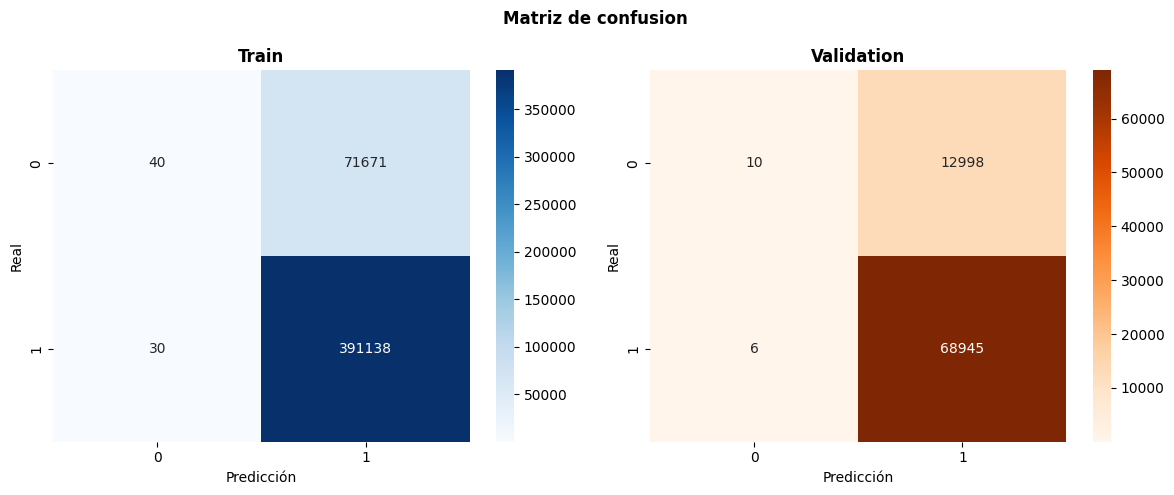

In [91]:
modeloBaseRegresionLogistica = LogisticRegression(max_iter = 1000)
modeloBaseRegresionLogistica.fit(X_train_scaled, y_train)

y_pred_train_modeloBaseRegresionLogistica = modeloBaseRegresionLogistica.predict(X_train_scaled)
y_pred_val_modeloBaseRegresionLogistica = modeloBaseRegresionLogistica.predict(X_val_scaled)

metricas_train_base = evaluar_metricas_clasificacion_binaria(y_pred_train_modeloBaseRegresionLogistica, y_train)
metricas_val_base = evaluar_metricas_clasificacion_binaria(y_pred_val_modeloBaseRegresionLogistica, y_val)
tabla_metricas_regresion_logistica_base = tabla_metricas(metricas_train_base, metricas_val_base, ["Accuracy", "Precision", "Recall", "F1"])
display(tabla_metricas_regresion_logistica_base)

labels = [0, 1]
cm_train = confusion_matrix(y_train, y_pred_train_modeloBaseRegresionLogistica, labels = labels)
cm_val = confusion_matrix(y_val, y_pred_val_modeloBaseRegresionLogistica, labels = labels)
plot_confusion_matrix(cm_train, cm_val, labels)

## Con rebalanceo predeterminado de scikit learn

,Train,Validation
Accuracy,0.616846,0.610500
Precision,0.905993,0.902934
Recall,0.609886,0.601703
F1,0.729020,0.722165


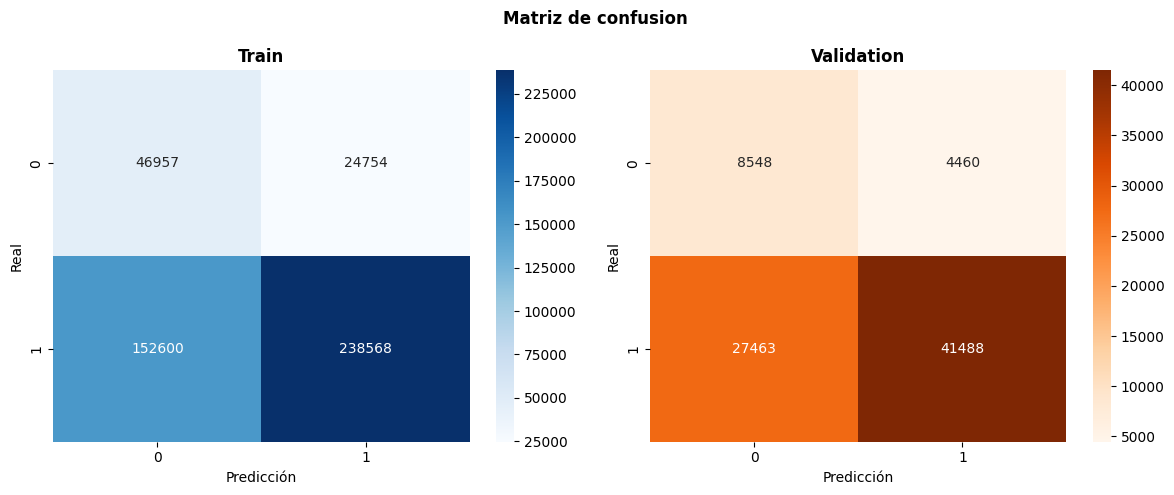

In [92]:
rebalanceo_1 = LogisticRegression(max_iter = 1000, class_weight = "balanced")
rebalanceo_1.fit(X_train_scaled, y_train)

y_pred_train_rebalanceo_1 = rebalanceo_1.predict(X_train_scaled)
y_pred_val_rebalanceo_1 = rebalanceo_1.predict(X_val_scaled)

metricas_train_balanced = evaluar_metricas_clasificacion_binaria(y_pred_train_rebalanceo_1, y_train)
metricas_val_balanced = evaluar_metricas_clasificacion_binaria(y_pred_val_rebalanceo_1, y_val)
tabla_metricas_regresion_logistica_1 = tabla_metricas(metricas_train_balanced, metricas_val_balanced, ["Accuracy", "Precision", "Recall", "F1"])
display(tabla_metricas_regresion_logistica_1)

cm_train = confusion_matrix(y_train, y_pred_train_rebalanceo_1, labels = labels)
cm_val = confusion_matrix(y_val, y_pred_val_rebalanceo_1, labels = labels)
plot_confusion_matrix(cm_train, cm_val, labels)

## Con pesos personalizados

En el contexto de este modelo, quiero que cuando decida que un libro es aceptado, esto casi siempre sea asi. Es por esto que voy a valorizar la metrica de Precision.

,Train,Validation
Accuracy,0.786426,0.782550
Precision,0.871155,0.868094
Recall,0.876979,0.874389
F1,0.874057,0.871230


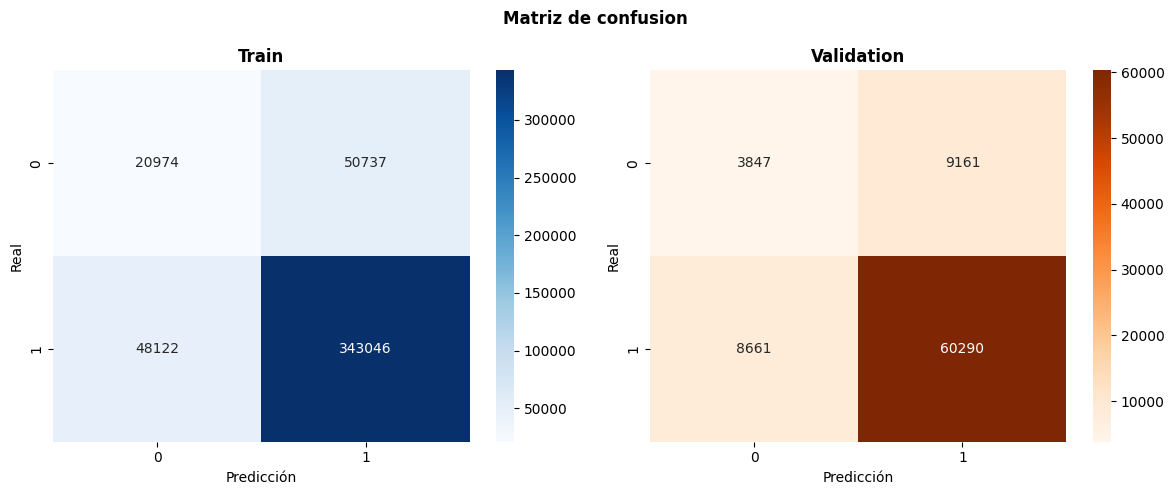

In [93]:
rebalanceo_2 = LogisticRegression(max_iter = 1000, class_weight = {0:3, 1:1})
rebalanceo_2.fit(X_train_scaled, y_train)

y_pred_train_rebalanceo_2 = rebalanceo_2.predict(X_train_scaled)
y_pred_val_rebalanceo_2 = rebalanceo_2.predict(X_val_scaled)

metricas_train_manual = evaluar_metricas_clasificacion_binaria(y_pred_train_rebalanceo_2, y_train)
metricas_val_manual = evaluar_metricas_clasificacion_binaria(y_pred_val_rebalanceo_2, y_val)
tabla_metricas_regresion_logistica_2 = tabla_metricas(metricas_train_manual, metricas_val_manual, ["Accuracy", "Precision", "Recall", "F1"])
display(tabla_metricas_regresion_logistica_2)

cm_train = confusion_matrix(y_train, y_pred_train_rebalanceo_2, labels = labels)
cm_val = confusion_matrix(y_val, y_pred_val_rebalanceo_2)
plot_confusion_matrix(cm_train, cm_val, labels)

## Con undersampling + pesos personalizados

In [94]:
pd.Series(y_train).value_counts().sort_index()

False     71711
True     391168
Name: count, dtype: int64

,Train,Validation
Accuracy,0.810117,0.807355
Precision,0.864035,0.861047
Recall,0.920093,0.919378
F1,0.891183,0.889257


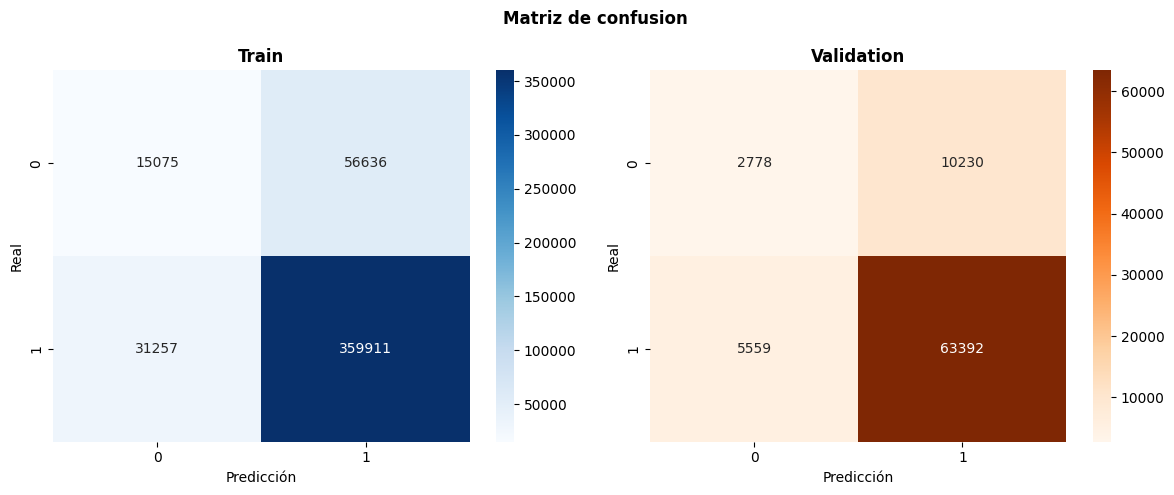

In [95]:
undersampling = RandomUnderSampler(sampling_strategy = {1: 300000}, random_state = 42)
X_res, y_res = undersampling.fit_resample(X_train, y_train) 

scaler = StandardScaler()
X_res_scaled = scaler.fit_transform(X_res)
X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)

rebalanceo_3 = LogisticRegression(class_weight = {0:2, 1:1}, max_iter = 1000)
rebalanceo_3.fit(X_res_scaled, y_res)

y_pred_train_rebalanceo_3 = rebalanceo_3.predict(X_train_scaled)
y_pred_val_rebalanceo_3 = rebalanceo_3.predict(X_val_scaled)

metricas_train_undersampling = evaluar_metricas_clasificacion_binaria(y_pred_train_rebalanceo_3, y_train)
metricas_val_undersampling = evaluar_metricas_clasificacion_binaria(y_pred_val_rebalanceo_3, y_val)
tabla_metricas_regresion_logistica_3 = tabla_metricas(metricas_train_undersampling, metricas_val_undersampling, ["Accuracy", "Precision", "Recall", "F1"])
display(tabla_metricas_regresion_logistica_3)

cm_train = confusion_matrix(y_train, y_pred_train_rebalanceo_3, labels = labels)
cm_val = confusion_matrix(y_val, y_pred_val_rebalanceo_3, labels = labels)
plot_confusion_matrix(cm_train, cm_val, labels)

# Modelo avanzado con features basicas

In [8]:
#variables que necesito para grid search, tanto para random forest como para xgboost
X_sub, _, y_sub_regresion, _, y_sub_clasificacion, _ = train_test_split(X_train_scaled, y_train, y_train, train_size=100000, stratify=y_train, random_state=42)

parametros_grid_search_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

parametros_grid_search_xgb = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
}

parametros_grid_search_rn = {
    "capas_ocultas": [[64], [128], [128, 64], [256, 128]],
    "dropout": [0.0, 0.2, 0.4],
    "lr": [0.01, 0.001, 0.0001],
    "funcion_activacion": [nn.ReLU, nn.LeakyReLU]
}

In [9]:
#Hago undersampling para los datos de train, uso el valor optimo encontrado en ModeloBase
cant_datos_deseada = {1: 300000}
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada, random_state = 42)
X_train_undersampling, y_train_undersampling = undersampling.fit_resample(X_train_scaled, y_train) 

#Hago undersampling para el subset usado en grid search
#cantidad de datos * 0,78 (proporcion de 300mil sobre 390mil)
cant_datos_deseada_sub = {1: 56150} 
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada_sub, random_state = 42)
X_sub_undersampling, y_sub_clasificacion_undersampling = undersampling.fit_resample(X_sub, y_sub_clasificacion) 

In [10]:
pesos_cost = {0:3, 1:1}
pesos_undersampling_cost = {0:2, 1:1}

### Random Forest

In [ ]:
def grid_search_rf_clasificacion(pesos, X, y):
    RandomForestGridSearchClasificacion = RandomForestClassifier(random_state = 42, class_weight = pesos)

    #uso las mismas opciones de hiperparametros q use en regresion, y los mismos indices para obtener los subconjuntos
    grid = GridSearchCV(estimator = RandomForestGridSearchClasificacion, param_grid = parametros_grid_search_rf, cv = 3, scoring = "precision", n_jobs = -1, verbose = 2)
    grid.fit(X, y)

    mejores_parametros = grid.best_params_
    print(f"Mejores parametros: {mejores_parametros}")
    print(f"Mejor precision CV: {grid.best_score_}")
    return mejores_parametros

def evaluar_modelo_rf_clasificacion(mejores_parametros, pesos, X_train, y_train, X_val, y_val):
    modeloRandomForestClasificacion = RandomForestClassifier(**mejores_parametros, random_state = 42, class_weight = pesos)
    modeloRandomForestClasificacion.fit(X_train, y_train)

    y_pred_train_modeloRandomForestClasificacion = (modeloRandomForestClasificacion.predict(X_train))
    y_pred_val_modeloRandomForestClasificacion = (modeloRandomForestClasificacion.predict(X_val))

    metricas_train = evaluar_metricas_clasificacion_binaria(y_pred_train_modeloRandomForestClasificacion, y_train)
    metricas_val = evaluar_metricas_clasificacion_binaria(y_pred_val_modeloRandomForestClasificacion, y_val)
    tabla_metricas_rf_clasificacion = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1"])
    print(tabla_metricas_rf_clasificacion)

    cm_train = confusion_matrix(y_train, y_pred_train_modeloRandomForestClasificacion, labels = [0, 1])
    cm_val = confusion_matrix(y_val, y_pred_val_modeloRandomForestClasificacion, labels = [0, 1])
    plot_confusion_matrix(cm_train, cm_val, labels = [0, 1])
    return tabla_metricas_rf_clasificacion, modeloRandomForestClasificacion, metricas_train, metricas_val

In [ ]:
mejores_parametros = grid_search_rf_clasificacion(pesos_undersampling_cost, X_sub_undersampling, y_sub_clasificacion_undersampling)

              Train  Validation
Accuracy   0.828375    0.830086
Precision  0.857653    0.873289
Recall     0.944033    0.933474
F1         0.898773    0.902379


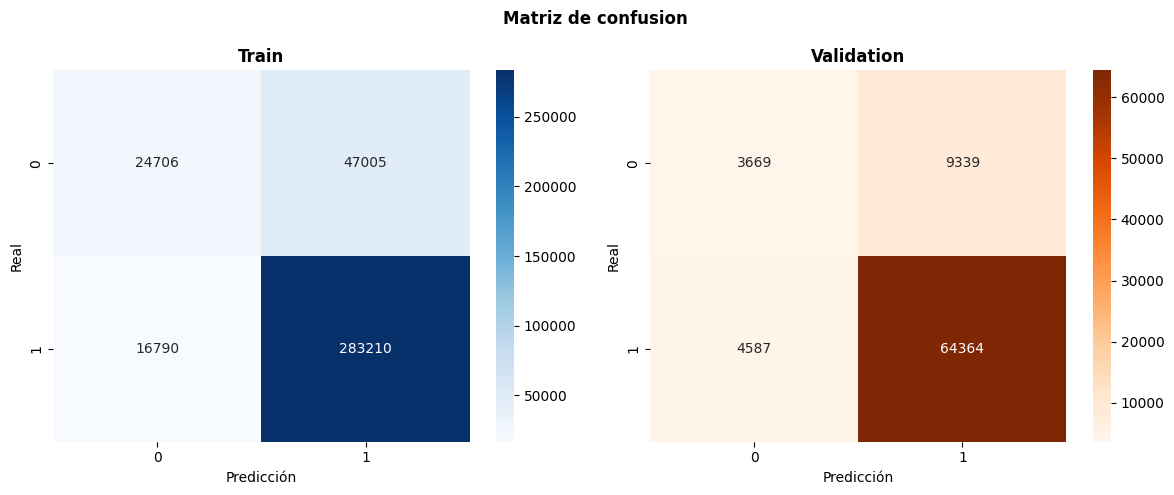

In [105]:
tabla_metricas_rf_clasificacion_undersampling_cost, modeloRandomForestClasificacion, metricas_train_rf, metricas_val_rf = evaluar_modelo_rf_clasificacion(mejores_parametros, pesos_undersampling_cost, X_train_undersampling, y_train_undersampling, X_val_scaled, y_val)
#plot_learning_curves_randomforest_classification(X_train_undersampling, y_train_undersampling, X_val_scaled, y_val, pesos = pesos_undersampling_cost, **mejores_parametros)

### XGBoost

In [11]:
def grid_search_xgb_clasificacion(pesos, X, y):
    pesos_transformados_sub = np.array([pesos[y_i] for y_i in y])
    XGBoostGridSearchClasificacion = XGBClassifier(objective = "binary:logistic", device = "cuda", tree_method = "hist", random_state = 42) 

    #uso los mismos indices para obtener los subconjuntos
    grid = GridSearchCV(estimator = XGBoostGridSearchClasificacion, param_grid = parametros_grid_search_xgb, cv = 3, scoring = "precision", n_jobs = 1, verbose = 1, error_score = "raise")
    grid.fit(X, y, sample_weight = pesos_transformados_sub)

    mejores_parametros = grid.best_params_
    print(f"Mejores parametros: {mejores_parametros}")
    print(f"Mejor precision CV: {grid.best_score_}")
    return mejores_parametros

def evaluar_modelo_xgb_clasificacion(mejores_parametros, pesos, X_train, y_train, X_val, y_val):
    pesos_transformados_train = np.array([pesos[y] for y in y_train])
    modeloXGBoostClasificacion = XGBClassifier(**mejores_parametros, objective = "binary:logistic", device = "cuda", tree_method = "hist", random_state = 42) 
    modeloXGBoostClasificacion.fit(X_train, y_train, sample_weight = pesos_transformados_train) #XGBoost no requiere obligatoriamnete que se escalen los valores, pero lo hag para poder comprar la feature importance

    y_pred_train = (modeloXGBoostClasificacion.predict(X_train))
    y_pred_val = (modeloXGBoostClasificacion.predict(X_val))

    #calculo las metricas usando las clases originales entre 1 y 5
    metricas_train = evaluar_metricas_clasificacion_binaria(y_pred_train, y_train)
    metricas_val = evaluar_metricas_clasificacion_binaria(y_pred_val, y_val)
    tabla_metricas_xgboost_clasificacion = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1"])
    print(tabla_metricas_xgboost_clasificacion)

    cm_train = confusion_matrix(y_train, y_pred_train, labels = [0, 1])
    cm_val = confusion_matrix(y_val, y_pred_val, labels = [0, 1])
    plot_confusion_matrix(cm_train, cm_val, labels = [0, 1])
    return tabla_metricas_xgboost_clasificacion, modeloXGBoostClasificacion, metricas_train, metricas_val

Fitting 3 folds for each of 108 candidates, totalling 324 fits


/home/czava/.local/lib/python3.10/site-packages/xgboost/core.py:751: UserWarning: [11:06:37] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Mejores parametros: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300, 'subsample': 0.8}
Mejor precision CV: 0.7281120586819451
              Train  Validation
Accuracy   0.798403    0.812492
Precision  0.856925    0.883201
Recall     0.900577    0.895549
F1         0.878209    0.889332


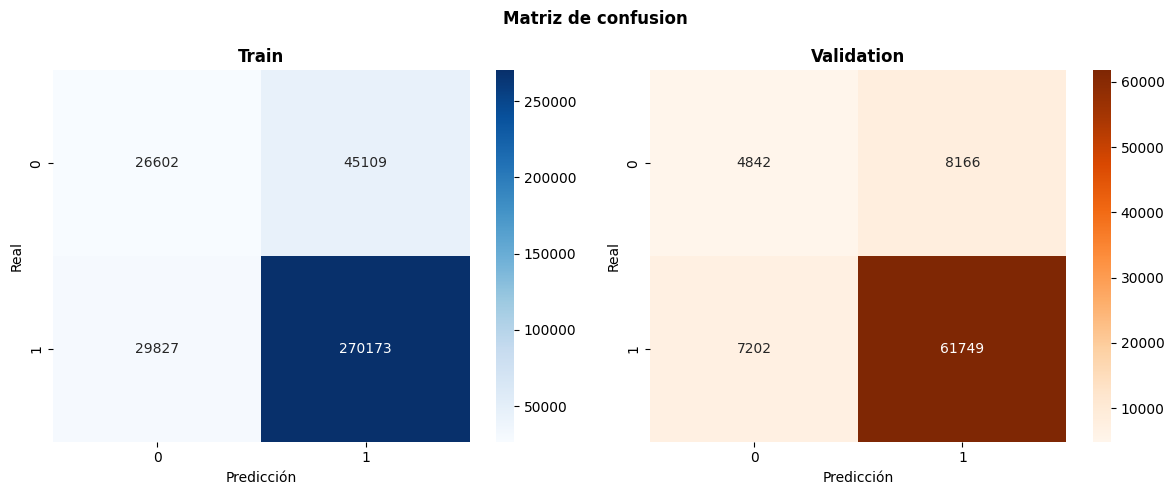

In [12]:
mejores_parametros = grid_search_xgb_clasificacion(pesos_undersampling_cost, X_sub_undersampling, y_sub_clasificacion_undersampling)
tabla_metricas_xgb_clasificacion_undersampling_cost, modeloXGBoostClasificacion, metricas_train_xgb, metricas_val_xgb = evaluar_modelo_xgb_clasificacion(mejores_parametros, pesos_undersampling_cost, X_train_undersampling, y_train_undersampling, X_val_scaled, y_val)

### Red neuronal

In [13]:
if torch.cuda.is_available():
  device = "cuda"
else:
  device = "cpu"
print(device)

cuda


In [14]:
def run_grid_search_pytorch_clasificacion(modelo, learning_rate, model_name, X_train, y_train, X_val, y_val, device, epochs = 100, pesos = None):
    #rebalanceo: transformo {0: ..., 1: ...} a lista
    weights = [pesos[0], pesos[1]]
    class_weights = torch.tensor(weights, dtype=torch.float32, device=device)

    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.Adam(modelo.parameters(), lr=learning_rate)
    train_loader, val_loader = make_dataloaders(X_train, y_train.astype(np.int64), X_val, y_val.astype(np.int64), n_batches=64)

    modelo.train_model(train_loader, val_loader, optimizer, loss_fn, device, epochs=epochs)
    y_pred_val = modelo.predict(X_val, device)
    precision_val = precision_score(y_val, y_pred_val, average="binary", zero_division=0)

    return precision_val

def run_experiment_pytorch_clasificacion(model, model_name, X_train, y_train, X_val, y_val, device, learning_rate = 0.001, epochs = 100, pesos = None):
    #rebalanceo: transformo {0: ..., 1: ...} a lista
    weights = [pesos[0], pesos[1]]
    class_weights = torch.tensor(weights, dtype=torch.float32, device=device)

    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    train_loader, val_loader = make_dataloaders(X_train, y_train.astype(np.int64), X_val, y_val.astype(np.int64), n_batches=64)

    train_losses, val_losses = model.train_model(train_loader, val_loader, optimizer, loss_fn, device, epochs=epochs, waiting=5)
    y_pred_train = model.predict(X_train, device)
    y_pred_val = model.predict(X_val, device)

    train_metrics = evaluar_metricas_clasificacion_binaria(y_pred_train, y_train)
    val_metrics = evaluar_metricas_clasificacion_binaria(y_pred_val, y_val)

    cm_train = confusion_matrix(y_train, y_pred_train, labels=[0, 1])
    cm_val = confusion_matrix(y_val, y_pred_val, labels=[0, 1])
    plot_confusion_matrix(cm_train, cm_val, labels = [0, 1])

    return train_metrics, val_metrics

In [15]:
mejor_precision = -np.inf
mejores_parametros = None

for capas_ocultas in parametros_grid_search_rn["capas_ocultas"]:
    for dropout in parametros_grid_search_rn["dropout"]:
        for lr in parametros_grid_search_rn["lr"]:
            for activacion in parametros_grid_search_rn["funcion_activacion"]:

                print(f"Probando: {capas_ocultas}, dropout={dropout}, lr={lr}, activacion={activacion.__name__}")
                modelo = MLP_clasificacion(input_size=X_sub.shape[1], hidden_layers=capas_ocultas, n_classes=2, activation=activacion, dropout=dropout).to(device)

                precision = run_grid_search_pytorch_clasificacion(modelo=modelo, learning_rate=lr, model_name="MLP Clasificacion", X_train=X_sub_undersampling, y_train=y_sub_clasificacion_undersampling, X_val=X_val_scaled, y_val=y_val, device=device, epochs=30, pesos = pesos_undersampling_cost)

                if precision > mejor_precision:
                    mejor_precision = precision
                    mejores_parametros = {"capas_ocultas": capas_ocultas, "dropout": dropout, "lr": lr, "activacion": activacion}

print(f"\nMejores parametros: {mejores_parametros}")

Probando: [64], dropout=0.0, lr=0.01, activacion=ReLU


PyTorch: 100%|██████████| 30/30 [00:46<00:00,  1.55s/epoca, epoch=30]


Probando: [64], dropout=0.0, lr=0.01, activacion=LeakyReLU


PyTorch: 100%|██████████| 30/30 [00:46<00:00,  1.53s/epoca, epoch=30]


Probando: [64], dropout=0.0, lr=0.001, activacion=ReLU


...

Probando: [256, 128], dropout=0.4, lr=0.0001, activacion=ReLU


PyTorch: 100%|██████████| 30/30 [00:45<00:00,  1.53s/epoca, epoch=30]


Probando: [256, 128], dropout=0.4, lr=0.0001, activacion=LeakyReLU


PyTorch: 100%|██████████| 30/30 [00:47<00:00,  1.58s/epoca, epoch=30]


Mejores parametros: {'capas_ocultas': [128], 'dropout': 0.0, 'lr': 0.01, 'activacion': <class 'torch.nn.modules.activation.ReLU'>}


PyTorch: 100%|██████████| 100/100 [11:27<00:00,  6.88s/epoca, epoch=100]


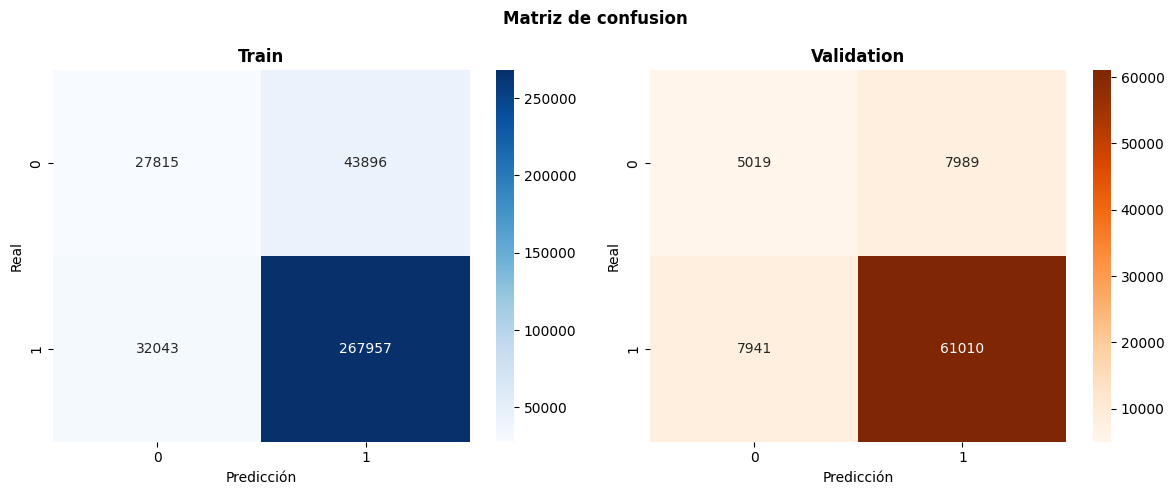

              Train  Validation
Accuracy   0.795704    0.805635
Precision  0.859241    0.884216
Recall     0.893190    0.884831
F1_score   0.875887    0.884523


In [16]:
modelo_clasificacion = MLP_clasificacion(input_size = X_train_scaled.shape[1], hidden_layers = mejores_parametros["capas_ocultas"], n_classes = 2, activation = mejores_parametros["activacion"], dropout = mejores_parametros["dropout"]).to(device)
metricas_train_mlp, metricas_val_mlp = run_experiment_pytorch_clasificacion(modelo_clasificacion, "Modelo Clasificacion", X_train_undersampling, y_train_undersampling, X_val_scaled, y_val, device, learning_rate = mejores_parametros["lr"], pesos = pesos_undersampling_cost)
tabla_metricas_mlp_clasificacion_undersampling = tabla_metricas(metricas_train_mlp, metricas_val_mlp, ["Accuracy", "Precision", "Recall", "F1_score"])
print(tabla_metricas_mlp_clasificacion_undersampling)

# Modelo avanzado con features avanzadas

In [17]:
#cargo los embeddings para sinopsis y titulo
descripcion_emb_train = np.load("descripcion_emb_train.npy")
descripcion_emb_val = np.load("descripcion_emb_val.npy")

sinopsis_libro = [f"description_emb_{num}" for num in range(50)]
features_avanzadas = features_base + sinopsis_libro

#preparo los dfs
descripcion_emb_train_df = pd.DataFrame(descripcion_emb_train, columns = sinopsis_libro, index = df_train.index)
descripcion_emb_val_df = pd.DataFrame(descripcion_emb_val, columns = sinopsis_libro, index = df_val.index)
df_val = df_val.join(descripcion_emb_val_df)